# Regression: description, causality, and uncertainty
**DS-UA 201 · Fall 2026**  
**Center for Data Science, New York University**  

**TA: Xiang Gao**

Oct 9, 2026

[Open in Colab](https://colab.research.google.com/github/xgao0o/DS-UA_201-Causal-Inference-Fall-2026/blob/main/labs/5-Regression.ipynb) (available after publication to the repository).

All datasets below are **synthetic teaching examples**, not empirical findings. No external data files or downloads are required.


## Goals and roadmap
By the end of this lab, you should be able to:

- distinguish a descriptive regression slope from a causal effect;
- calculate ordinary least squares (OLS) using centered sums and a design matrix;
- explain why a regression can be linear in its coefficients while using nonlinear features;
- connect binary-treatment regression to the difference in means from Week 4; and
- choose standard errors that match the assumptions about the data.



## Setup
Run cells from top to bottom, or choose **Restart Kernel and Run All Cells**. We use NumPy, pandas, Matplotlib, SciPy, and statsmodels; each simulation has its own fixed seed. For local installation, see the [course README](../README.md). If needed, install `numpy pandas matplotlib scipy statsmodels` with `pip` (or `%pip` in Colab).

Last week, random assignment justified comparing treated and control means. Today we show that the same comparison is an OLS coefficient, then ask when a regression coefficient has a causal interpretation.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (7, 4),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE, RED = "#426d89", "#a33f45"


## 1. Descriptive regression and OLS
### A population parameter: the best linear predictor
Let $X$ be a predictor and $Y$ an outcome with finite second moments and $\operatorname{Var}(X)>0$. The **population regression coefficients** solve

$$ (\beta_0,\beta_1)=\arg\min_{b_0,b_1}\mathbb E[(Y-b_0-b_1X)^2]. $$

The **residual** is $\varepsilon=Y-\beta_0-\beta_1X$. The first-order conditions give

$$\mathbb E[\varepsilon]=0,\qquad \mathbb E[X\varepsilon]=0,$$

so

$$\beta_1=\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)},\qquad
\beta_0=\mathbb E[Y]-\beta_1\mathbb E[X].$$

These are properties of the best linear approximation. They do **not** imply independence of $X$ and $\varepsilon$, that $\mathbb E[\varepsilon\mid X]=0$, or that changing $X$ would change $Y$ by $\beta_1$.


### An estimator: replace the expected loss with a sample average
For observed pairs $(x_i,y_i)$, define $\bar x=n^{-1}\sum_i x_i$ and $\bar y=n^{-1}\sum_i y_i$. The **OLS estimator** minimizes

$$\frac1n\sum_{i=1}^n(y_i-b_0-b_1x_i)^2.$$

When the observed $x_i$ are not all equal,

$$\hat\beta_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},\qquad
\hat\beta_0=\bar y-\hat\beta_1\bar x.$$

The numerator also equals $\sum_i x_i y_i-n\bar x\bar y$. The factor $n$ matters. Sample covariance divided by sample variance gives this same slope if both use the same denominator.

Write $\hat y_i=\hat\beta_0+\hat\beta_1x_i$ and $\hat\varepsilon_i=y_i-\hat y_i$. With an intercept, $\sum_i\hat\varepsilon_i=0$ and $\sum_i x_i\hat\varepsilon_i=0$ up to numerical precision. These **sample identities** do not establish causal assumptions. Under i.i.d. sampling and the moment conditions above, OLS consistently estimates the population projection coefficients; finite-sample unbiasedness needs additional assumptions.


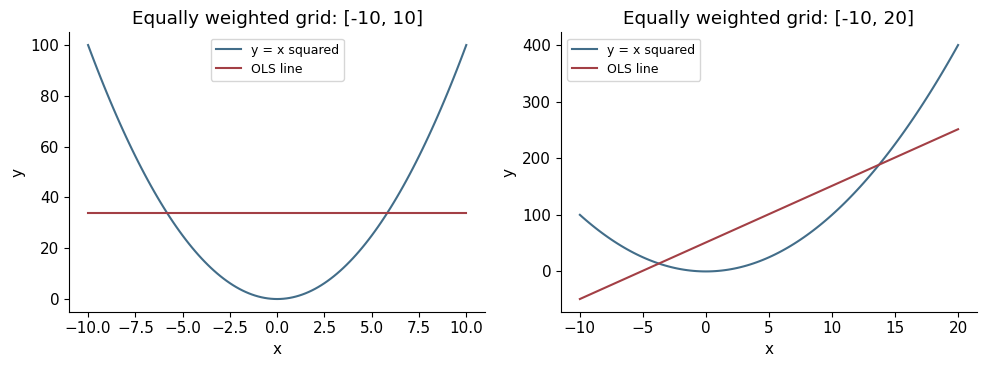

,Intercept,Slope,Mean squared error
Interval,,,
"[-10, 10]",33.889,-0.0,918.577
"[-10, 20]",51.250,10.0,4650.297


In [2]:
def simple_ols(x, y):
    """Return the intercept and slope from equal-length 1D arrays."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    x_centered, y_centered = x - x.mean(), y - y.mean()
    denominator = x_centered @ x_centered
    if denominator == 0:
        raise ValueError("OLS needs variation in x to estimate a slope.")
    slope = (x_centered @ y_centered) / denominator
    intercept = y.mean() - slope * x.mean()
    return np.array([intercept, slope])

# These are deterministic grids, not random samples from a population.
intervals = [(-10, 10), (-10, 20)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
quadratic_rows = []
for ax, (left, right) in zip(axes, intervals):
    x_grid = np.linspace(left, right, 121)
    y_grid = x_grid**2
    intercept, slope = simple_ols(x_grid, y_grid)
    fitted = intercept + slope * x_grid
    quadratic_rows.append({"Interval": f"[{left}, {right}]",
                           "Intercept": intercept, "Slope": slope,
                           "Mean squared error": np.mean((y_grid - fitted)**2)})
    ax.plot(x_grid, y_grid, color=BLUE, label="y = x squared")
    ax.plot(x_grid, fitted, color=RED, label="OLS line")
    ax.set(title=f"Equally weighted grid: [{left}, {right}]", xlabel="x", ylabel="y")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
display(pd.DataFrame(quadratic_rows).set_index("Interval").round(3))


The same curved relationship gives different fitted slopes when we change the distribution of predictor values. On the symmetric grid the slope is zero, although $y$ depends on $x$. The intercept is the **finite grid average of $x^2$**, not the value 1 from the standard-normal population example.

### Exercise 1: a zero slope
1. Does a zero slope on the symmetric grid mean $X$ and $Y$ are independent?
2. If you add 100 to every $y_i$, what happens to the slope and intercept? Try it with `simple_ols`.

<details><summary>Answer</summary>

1. No. $Y=X^2$ is deterministic and nonconstant. The positive and negative parts of the curve cancel in the linear covariance.
2. The slope is unchanged because centering removes the added constant. The intercept increases by 100.

```python
original = simple_ols(x_grid, y_grid)
shifted = simple_ols(x_grid, y_grid + 100)
print(shifted - original)  # [100., 0.] up to rounding
```

</details>


## 2. Matrix OLS and polynomial features
### The intercept is a column of ones
Let $\mathbf X$ be the **design matrix**, with one row per observation and one column per coefficient. For a single predictor,

$$\mathbf X=\begin{bmatrix}1&x_1\\\vdots&\vdots\\1&x_n\end{bmatrix},\qquad
\hat{\boldsymbol\beta}=\begin{bmatrix}\hat\beta_0\\\hat\beta_1\end{bmatrix},\qquad
\hat{\mathbf y}=\mathbf X\hat{\boldsymbol\beta}.$$

For $k$ linearly independent columns, the unique OLS solution is

$$\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y.$$

In code, use `np.linalg.lstsq` to solve the least-squares problem without explicitly inverting $\mathbf X^\top\mathbf X$. Adding the ones column **includes** the intercept; it does not remove it. Duplicate columns make coefficients non-unique.


In [3]:
# Work on a centered grid so coefficients are easy to interpret.
x = np.linspace(-3, 3, 121)
y = x**2
X_line = np.column_stack([np.ones(len(x)), x])
beta_line, _, rank_line, _ = np.linalg.lstsq(X_line, y, rcond=None)
residual_line = y - X_line @ beta_line

display(pd.DataFrame({"Centered-sum OLS": simple_ols(x, y),
                      "Matrix OLS": beta_line}, index=["Intercept", "Slope"]).round(6))
print("Design matrix shape:", X_line.shape, "  Rank:", rank_line)
assert np.allclose(beta_line, simple_ols(x, y))
assert np.allclose(X_line.T @ residual_line, 0, atol=1e-9)


,Centered-sum OLS,Matrix OLS
Intercept,3.05,3.05
Slope,0.00,0.00


Design matrix shape: (121, 2)   Rank: 2


### Nonlinear in $x$, linear in the coefficients
Add a column for $x^2$:

$$\hat y=\hat b_0+\hat b_1x+\hat b_2x^2.$$

This is **polynomial regression** with explicit features $1,x,x^2$. It is still linear in the coefficients.


,Quadratic coefficients
Intercept,-0.0
x,-0.0
x squared,1.0


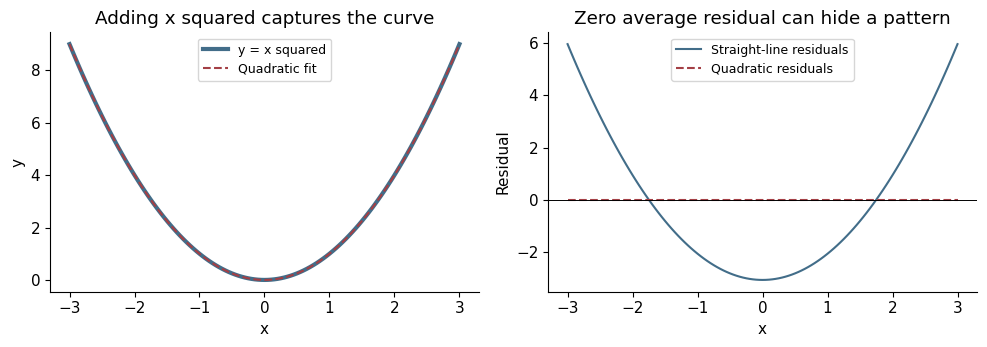

In [4]:
X_quad = np.column_stack([np.ones(len(x)), x, x**2])
beta_quad = np.linalg.lstsq(X_quad, y, rcond=None)[0]
fitted_quad = X_quad @ beta_quad
display(pd.Series(beta_quad, index=["Intercept", "x", "x squared"],
                  name="Quadratic coefficients").round(6).to_frame())
assert np.allclose(beta_quad, [0, 0, 1], atol=1e-10)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(x, y, color=BLUE, linewidth=3, label="y = x squared")
axes[0].plot(x, fitted_quad, color=RED, linestyle="--", label="Quadratic fit")
axes[0].set(title="Adding x squared captures the curve", xlabel="x", ylabel="y")
axes[0].legend(fontsize=9)
axes[1].plot(x, residual_line, color=BLUE, label="Straight-line residuals")
axes[1].plot(x, y - fitted_quad, color=RED, linestyle="--", label="Quadratic residuals")
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set(title="Zero average residual can hide a pattern", xlabel="x", ylabel="Residual")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()


### Exercise 2: what does a perfect fit establish?
Why does the quadratic fit have essentially zero residuals here? Does that establish a causal effect of $X$ on $Y$?

<details><summary>Answer</summary>

The constructed data satisfy $y=x^2$ exactly, without noise, and the design matrix includes that feature. The coefficient vector $(0,0,1)$ reproduces every point. Fit alone says nothing about interventions in an empirical study: causal interpretation requires a causal model and identification assumptions. With noisy data, adding polynomial terms also need not improve predictions on new observations.

</details>


## 3. Causal regression and identification
### A causal model adds substantive assumptions
Let $S$ denote a treatment and $U$ denote other causes of the outcome. Suppose the **all-causes model** is

$$Y(s,U)=\alpha_0+\alpha_1s+U.$$

Changing $s$ by one while holding $U$ fixed changes the outcome by $\alpha_1$. For binary treatment, $Y(1)-Y(0)=\alpha_1$ for every unit, so the population ATE is also $\alpha_1$. This additive, constant-effect model is an assumption about potential outcomes.

We may center $U$ by defining $\widetilde U=U-\mathbb E[U]$ and $\widetilde\alpha_0=\alpha_0+\mathbb E[U]$. This makes $\mathbb E[\widetilde U]=0$ without changing the model. **Centering does not remove confounding.**

Using observed $Y=\alpha_0+\alpha_1S+U$, the population descriptive slope is

$$\beta_1=\frac{\operatorname{Cov}(S,Y)}{\operatorname{Var}(S)}
=\alpha_1+\frac{\operatorname{Cov}(S,U)}{\operatorname{Var}(S)}.$$

Thus $\beta_1=\alpha_1$ if $\operatorname{Cov}(S,U)=0$. Independence $S\perp U$ is a stronger sufficient condition. With centered $U$, independence implies $\mathbb E[SU]=\mathbb E[S]\mathbb E[U]=0$. The condition $\mathbb E[U]=0$ alone does not imply this.


### A synthetic attendance example: two assignment mechanisms
Baseline preparation $U\sim N(0,1)$ affects a numerical performance score. Set $Y(0)=50+8U$ and $Y(1)=Y(0)+6$ **before assigning treatment**. Scores are unbounded teaching outcomes, not grades restricted to 0–100.

Compare random assignment to selection where better-prepared students are more likely to attend. We observe one potential outcome per student under each hypothetical mechanism. The two datasets describe alternative scenarios for the same synthetic students; they are not two independent studies.


,True effect,OLS slope,Slope minus true effect,Baseline imbalance
Assignment,,,,
Random assignment,6,6.141,0.141,0.141
Selection on preparation,6,14.716,8.716,8.716


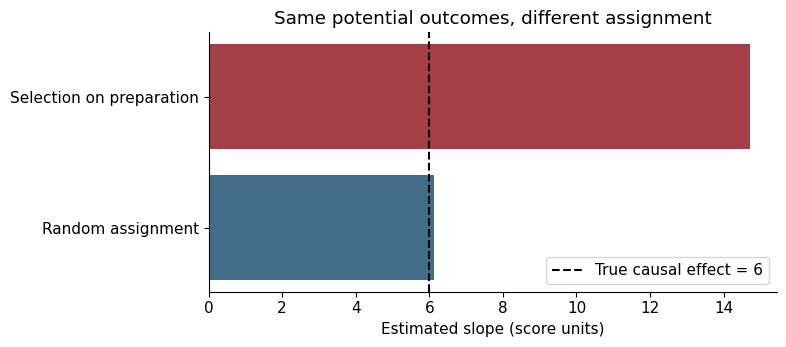

In [5]:
causal_rng = np.random.default_rng(202605)
n = 1_000
preparation = causal_rng.normal(size=n)
y0 = 50 + 8 * preparation
y1 = y0 + 6
s_random = causal_rng.binomial(1, 0.5, size=n)
attendance_probability = 1 / (1 + np.exp(-1.5 * preparation))
s_selected = causal_rng.binomial(1, attendance_probability)

study_data = {}
causal_rows = []
for name, s in [("Random assignment", s_random), ("Selection on preparation", s_selected)]:
    observed_y = np.where(s == 1, y1, y0)
    study_data[name] = pd.DataFrame({"S": s, "Y": observed_y})
    b0, b1 = simple_ols(s, observed_y)
    # U in the additive causal model is 8 * preparation.
    # This component is observable here only because we built the simulation.
    imbalance_component = simple_ols(s, 8 * preparation)[1]
    fitted_residuals = observed_y - b0 - b1 * s
    causal_rows.append({"Assignment": name, "True effect": 6,
                        "OLS slope": b1, "Slope minus true effect": b1 - 6,
                        "Baseline imbalance": imbalance_component})
    assert np.isclose(b1, 6 + imbalance_component)
    assert np.isclose(s @ fitted_residuals, 0, atol=1e-8)
causal_table = pd.DataFrame(causal_rows).set_index("Assignment")
display(causal_table.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(causal_table.index, causal_table["OLS slope"], color=[BLUE, RED])
ax.axvline(6, color="black", linestyle="--", label="True causal effect = 6")
ax.set(xlabel="Estimated slope (score units)", title="Same potential outcomes, different assignment")
ax.legend()
fig.tight_layout()
plt.show()


Under random assignment, baseline imbalance is sampling noise. Selection on preparation creates systematic confounding: the descriptive slope mixes the attendance effect with differences in preparation. The table's “slope minus true effect” is a **realized estimation error**, not an estimate of repeated-sampling bias by itself.


## 4. Binary treatment and experiments
### Why an OLS slope equals a difference in means
Let $S\in\{0,1\}$, $p=P(S=1)$ with $0<p<1$, and $\mu_s=\mathbb E[Y\mid S=s]$. Since $S^2=S$,

$$\operatorname{Var}(S)=p(1-p),\qquad
\operatorname{Cov}(S,Y)=p\mu_1-p\{p\mu_1+(1-p)\mu_0\}
=p(1-p)(\mu_1-\mu_0).$$

Therefore the population descriptive slope is $\beta_1=\mu_1-\mu_0$. In a sample containing both arms, OLS **with an intercept and only $S$ as a predictor** gives exactly

$$\hat\beta_0=\bar y_0,\qquad\hat\beta_1=\bar y_1-\bar y_0.$$

This algebra holds even for confounded data. For a causal interpretation, we need consistency $Y=Y(S)$, well-defined treatment without interference, and an assignment condition such as $S\perp(Y(0),Y(1))$. Then

$$\mathbb E[Y\mid S=1]-\mathbb E[Y\mid S=0]
=\mathbb E[Y(1)]-\mathbb E[Y(0)]=\operatorname{ATE}.$$



In [6]:
experiment = study_data["Random assignment"]
group_means = experiment.groupby("S")["Y"].mean()
X_experiment = sm.add_constant(experiment["S"])
experiment_fit = sm.OLS(experiment["Y"], X_experiment).fit()
difference_in_means = group_means.loc[1] - group_means.loc[0]

display(pd.Series({
    "Control mean": group_means.loc[0],
    "Regression intercept": experiment_fit.params["const"],
    "Difference in means": difference_in_means,
    "Regression slope": experiment_fit.params["S"],
    "Known synthetic ATE": np.mean(y1 - y0),
}, name="Score units").round(4).to_frame())
assert np.isclose(experiment_fit.params["const"], group_means.loc[0])
assert np.isclose(experiment_fit.params["S"], difference_in_means)


,Score units
Control mean,50.1693
Regression intercept,50.1693
Difference in means,6.1411
Regression slope,6.1411
Known synthetic ATE,6.0000


### Keep the four steps separate

| Step | This experiment |
|---|---|
| Causal parameter | $\mathbb E[Y(1)-Y(0)]$ |
| Identification | Random assignment, consistency, well-defined treatment/no interference, both arms possible |
| Estimator | OLS slope $\hat\beta_1=\bar Y_1-\bar Y_0$ |
| Realized estimate | The numerical slope printed above |

### Exercise 3: removing the intercept
What would the coefficient from regressing $Y$ on $S$ **without an intercept** equal? Try `sm.OLS(experiment["Y"], experiment[["S"]]).fit().params`.

<details><summary>Answer</summary>

It equals $\sum_i S_iY_i/\sum_i S_i^2=\bar y_1$, the treated-group mean. Without an intercept the fitted control-group mean is forced to zero, so the coefficient is not the difference in means. Include the intercept for the comparison derived above.

</details>


## 5. Regression standard errors
### Standard errors quantify uncertainty, not identification
A coefficient estimate varies across repeated samples or assignments. Its **standard error (SE)** estimates the standard deviation of that sampling distribution. A small SE cannot eliminate confounding.

For a correctly specified conditional-mean model $\mathbf y=\mathbf X\boldsymbol\beta+\mathbf u$ with $\mathbb E[\mathbf u\mid\mathbf X]=0$ and full column rank, let $\boldsymbol\Sigma=\operatorname{Var}(\mathbf u\mid\mathbf X)$. Then

$$\operatorname{Var}(\hat{\boldsymbol\beta}\mid\mathbf X)
=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\boldsymbol\Sigma\mathbf X(\mathbf X^\top\mathbf X)^{-1}.$$

If errors are conditionally uncorrelated with a common variance (**homoskedasticity**), $\boldsymbol\Sigma=\sigma^2\mathbf I$. This simplifies to $\sigma^2(\mathbf X^\top\mathbf X)^{-1}$, estimated using $\hat\sigma^2=\sum_i\hat u_i^2/(n-k)$, where $k$ includes the intercept.

For independent observations whose error variances differ (**heteroskedasticity**), use a heteroskedasticity-consistent covariance estimate. We use **HC2**, a version that adjusts squared residuals for leverage. For an intercept-plus-binary-treatment regression, its slope SE equals the familiar

$$\widehat{\operatorname{SE}}(\bar Y_1-\bar Y_0)
=\sqrt{\frac{s_1^2}{n_1}+\frac{s_0^2}{n_0}}.$$

Here $s_s^2$ is the sample variance within arm $s$, using denominator $n_s-1$. HC2 supports large-sample inference with independent observations and suitable moments; it does not address within-cluster dependence. statsmodels' `.fit()` uses homoskedastic SEs by default, so request robust SEs explicitly.


,Slope,SE,95% lower,95% upper
SE method,,,,
Homoskedastic,6.517,0.659,5.226,7.807
HC2,6.517,1.165,4.233,8.800


Arm sizes: treated = 131, control = 469
SE from the two group variances: 1.164864
HC2 regression SE:              1.164864
Population ATE: 6; finite-sample average effect: 6.282


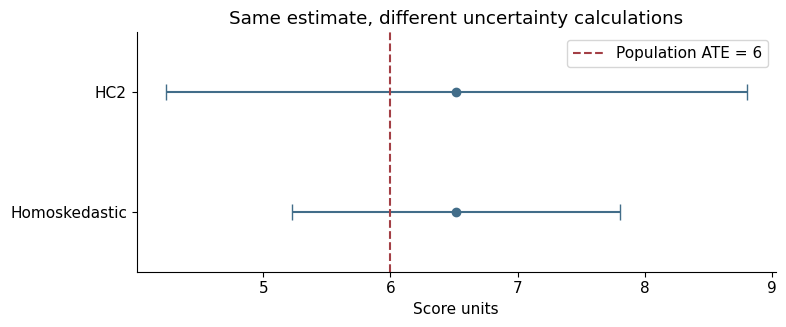

In [ ]:
# A NEW synthetic experiment with unequal variances and heterogeneous effects.
se_rng = np.random.default_rng(5026)
n_se = 600
shock = se_rng.normal(size=n_se)
potential_control = 50 + 3 * shock
potential_treated = 56 + 12 * shock
treatment = se_rng.binomial(1, 0.25, size=n_se)
outcome = np.where(treatment == 1, potential_treated, potential_control)
X_se = np.column_stack([np.ones(n_se), treatment])
model_se = sm.OLS(outcome, X_se)
fit_homoskedastic = model_se.fit()
fit_hc2 = model_se.fit(cov_type="HC2", use_t=False)

# Compare covariance choices using the SAME large-sample normal critical value.
z_critical = stats.norm.ppf(0.975)
se_rows = []
for name, fitted_model in [("Homoskedastic", fit_homoskedastic), ("HC2", fit_hc2)]:
    estimate, standard_error = fitted_model.params[1], fitted_model.bse[1]
    se_rows.append({"SE method": name, "Slope": estimate, "SE": standard_error,
                    "95% lower": estimate - z_critical * standard_error,
                    "95% upper": estimate + z_critical * standard_error})
se_table = pd.DataFrame(se_rows).set_index("SE method")
display(se_table.round(3))

treated_y, control_y = outcome[treatment == 1], outcome[treatment == 0]
welch_se = np.sqrt(treated_y.var(ddof=1) / len(treated_y)
                   + control_y.var(ddof=1) / len(control_y))
print(f"Arm sizes: treated = {len(treated_y)}, control = {len(control_y)}")
print(f"SE from the two group variances: {welch_se:.6f}")
print(f"HC2 regression SE:              {fit_hc2.bse[1]:.6f}")
print(f"Population ATE: 6; finite-sample average effect: "
      f"{np.mean(potential_treated - potential_control):.3f}")
assert np.isclose(fit_hc2.bse[1], welch_se)
assert np.allclose(fit_homoskedastic.params, fit_hc2.params)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(se_table["Slope"], np.arange(2), xerr=z_critical * se_table["SE"],
            fmt="o", capsize=6, color=BLUE)
ax.set(yticks=np.arange(2), yticklabels=se_table.index,
       xlabel="Score units", title="Same estimate, different uncertainty calculations")
ax.axvline(6, color=RED, linestyle="--", label="Population ATE = 6")
ax.legend()
ax.margins(y=0.5)
fig.tight_layout()
plt.show()


In this simulation, the treated arm is smaller and has more variable outcomes. The common-variance calculation understates uncertainty. Robust SEs can be larger **or smaller** in other datasets; choose the method from the design and assumptions, not from the p-value it gives.

### Exercise 4: interpret the uncertainty
1. Does switching from homoskedastic to HC2 standard errors change the coefficient estimate?
2. Does an HC2 interval excluding zero prove that the regression is causal?
3. Would HC2 handle students whose outcomes share a classroom-level shock?

<details><summary>Answer</summary>

1. No. The fitting criterion and coefficients are unchanged; the estimated covariance and resulting intervals/tests change.
2. No. The interval concerns the parameter identified under the study's assumptions. Robust SEs cannot establish random assignment or repair confounding.
3. No. Ordinary HC2 treats observations as independent. Dependence within classrooms calls for inference that reflects the cluster structure; see Optional B.

</details>


## Optional A. Polynomial ridge regression
We can add a penalty to polynomial-feature regression. **Ridge regression** shrinks coefficients by solving

$$\min_{b_0,\ldots,b_d}\left\{\sum_i\left[y_i-b_0-\sum_{j=1}^d b_j z_i^j\right]^2
+\lambda\sum_{j=1}^d b_j^2\right\},\qquad\lambda\geq0.$$

Here $z$ is a scaled predictor. The intercept is **not penalized**. This definition uses a sum of squared errors; using a mean instead would change the scale of $\lambda$. Feature scaling also changes what a given penalty means.

Retain $y=x^2$ as the target, add synthetic noise, and compare a degree-8 fit with and without shrinkage. Scale $x$ to $[-1,1]$ and solve an augmented least-squares problem to avoid explicit matrix inversion. This is polynomial ridge regression in an explicit feature space, not a general kernel-method lesson.


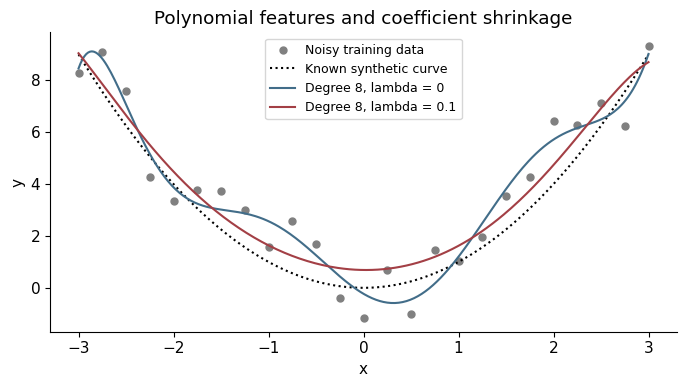

,Training MSE,Curve-grid MSE
lambda,,
0.0,0.4704,0.9402
0.1,1.0362,0.3551


In [ ]:
ridge_rng = np.random.default_rng(5601)
x_train = np.linspace(-3, 3, 25)
y_train = x_train**2 + ridge_rng.normal(0, 1.2, len(x_train))
x_plot = np.linspace(-3, 3, 300)
degree = 8
Phi_train = np.column_stack([(x_train / 3)**j for j in range(degree + 1)])
Phi_plot = np.column_stack([(x_plot / 3)**j for j in range(degree + 1)])
penalty = np.eye(degree + 1)
penalty[0, 0] = 0  # Do not penalize the intercept.

fig, ax = plt.subplots()
ax.scatter(x_train, y_train, color="gray", s=25, label="Noisy training data")
ax.plot(x_plot, x_plot**2, color="black", linestyle=":", label="Known synthetic curve")
ridge_rows = []
for lam, color in [(0.0, BLUE), (0.1, RED)]:
    augmented_X = np.vstack([Phi_train, np.sqrt(lam) * penalty])
    augmented_y = np.concatenate([y_train, np.zeros(degree + 1)])
    coefficients = np.linalg.lstsq(augmented_X, augmented_y, rcond=None)[0]
    ridge_rows.append({"lambda": lam,
                       "Training MSE": np.mean((y_train - Phi_train @ coefficients)**2),
                       "Curve-grid MSE": np.mean((x_plot**2 - Phi_plot @ coefficients)**2)})
    ax.plot(x_plot, Phi_plot @ coefficients, color=color, label=f"Degree 8, lambda = {lam:g}")
ax.set(xlabel="x", ylabel="y", title="Polynomial features and coefficient shrinkage")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
display(pd.DataFrame(ridge_rows).set_index("lambda").round(4))


The curve-grid MSE compares predictions with the known noiseless curve on an equally weighted grid. It is a simulation diagnostic, not an empirical test-set result. In an actual prediction task, tune the degree and penalty using held-out data or cross-validation. A lower training error need not imply better prediction, and prediction performance does not identify a causal effect.

### Optional exercise A
Increase `lam` or change `degree` and rerun the optional example. Must increasing the penalty improve the curve-grid MSE?

<details><summary>Answer</summary>

No. Shrinkage can reduce unstable fitting of noise, but excessive shrinkage can underfit the curve. Its usefulness depends on the data and features. Comparing only training errors rewards a more flexible model; it does not measure generalization.

</details>


## Optional B. Clustered standard errors
Here is an example of outcomes sharing a cluster-level shock. Imagine students in **60 independent classrooms**, with 20 students each. Treatment is randomized once per classroom, and a common classroom shock affects all its students:

$$Y_{ig}(s)=50+2s+A_g+e_{ig},$$

where $A_g$ is the classroom shock and $e_{ig}$ is student-specific noise. Generate these potential outcomes first, then assign classrooms. The treatment effect is 2 by construction.

Heteroskedasticity-robust SEs alone do not allow residual dependence within a classroom. A **cluster-robust** covariance estimate allows arbitrary within-classroom dependence while assuming independence across classrooms. With $\hat{\mathbf u}_g$ the residual vector in cluster $g$,

$$\widehat V_{\mathrm{cluster}}
=c\,(\mathbf X^\top\mathbf X)^{-1}
\left(\sum_{g=1}^G\mathbf X_g^\top\hat{\mathbf u}_g\hat{\mathbf u}_g^\top\mathbf X_g\right)
(\mathbf X^\top\mathbf X)^{-1}.$$

The conventional small-sample multiplier used below is $c=\frac{G}{G-1}\frac{n-1}{n-k}$. The approximation relies on enough independent clusters; many students in a few classrooms do not substitute for many classrooms. Choose clusters from the assignment and dependence structure. Clustering does not fix confounding, interference across classrooms, or dependence between classrooms.


In [ ]:
cluster_rng = np.random.default_rng(5602)
n_clusters, per_cluster = 60, 20
classroom = np.repeat(np.arange(n_clusters), per_cluster)
classroom_shock = cluster_rng.normal(0, 3, n_clusters)
student_shock = cluster_rng.normal(0, 1, len(classroom))
cluster_y0 = 50 + classroom_shock[classroom] + student_shock
cluster_y1 = cluster_y0 + 2
classroom_treatment = cluster_rng.binomial(1, 0.5, n_clusters)
cluster_s = classroom_treatment[classroom]
cluster_y = np.where(cluster_s == 1, cluster_y1, cluster_y0)

cluster_model = sm.OLS(cluster_y, np.column_stack([np.ones(len(classroom)), cluster_s]))
fit_independent = cluster_model.fit(cov_type="HC2", use_t=False)
fit_clustered = cluster_model.fit(
    cov_type="cluster",
    cov_kwds={"groups": classroom, "use_correction": True, "df_correction": True},
    use_t=True,
)
# Conventional cluster inference uses t with G - 1 degrees of freedom here.
cluster_critical = stats.t.ppf(0.975, df=n_clusters - 1)
cluster_rows = []
for name, fit_result, critical in [
    ("HC2: treats students as independent", fit_independent, z_critical),
    ("Clustered by classroom", fit_clustered, cluster_critical),
]:
    b, se_b = fit_result.params[1], fit_result.bse[1]
    cluster_rows.append({"Method": name, "Slope": b, "SE": se_b,
                         "95% lower": b - critical * se_b,
                         "95% upper": b + critical * se_b})
display(pd.DataFrame(cluster_rows).set_index("Method").round(3))
print(f"Students: {len(classroom)}; independent classrooms: {n_clusters}")
print(f"Treated classrooms: {classroom_treatment.sum()}; "
      f"control classrooms: {n_clusters - classroom_treatment.sum()}")
assert np.allclose(fit_independent.params, fit_clustered.params)

# Equal classroom sizes make this point estimate equal to the classroom-mean comparison.
class_means = cluster_y.reshape(n_clusters, per_cluster).mean(axis=1)
class_difference = (class_means[classroom_treatment == 1].mean()
                    - class_means[classroom_treatment == 0].mean())
assert np.isclose(fit_clustered.params[1], class_difference)


,Slope,SE,95% lower,95% upper
Method,,,,
HC2: treats students as independent,0.621,0.171,0.287,0.956
Clustered by classroom,0.621,0.725,-0.828,2.071


Students: 1200; independent classrooms: 60
Treated classrooms: 35; control classrooms: 25


The point estimate is unchanged, but the standard error is much larger after allowing for the shared classroom shocks in this simulation. The table also uses a $t_{G-1}$ reference for the clustered interval; this is a conventional approximation, not an exact guarantee for arbitrary clusters. Cluster SEs need not always exceed individual-level SEs, and very few or highly unequal clusters require additional care.

### Optional exercise B
Why does having 1,200 students not give us 1,200 independent treatment assignments? How does this connect to the school-level analysis in Week 4?

<details><summary>Answer</summary>

Each classroom receives one assignment shared by all 20 students, and its students share a shock. There are 60 independent assignment units. As in Week 4, analyzing group means makes the independent units visible. Equal classroom sizes make the group-mean and individual-level treatment coefficients agree here; their weighting can differ with unequal sizes. Cluster-robust inference is a way to retain the individual rows while accounting for within-group dependence.

</details>
